# A/B-тест NewsPortal: платные блоки наверху ленты или внизу?

**Бизнес-вопрос:** если поставить платные блоки наверх ленты вместо органического, мы заработаем больше или потеряем на том, что люди меньше читают сайт?

**Дизайн эксперимента.** Под статьёй издателя показывается лента из 5 блоков:
- **Группа A (контроль):** сверху 1 органический блок, снизу 4 платных.
- **Группа B (тест):** сверху 4 платных блока, снизу 1 органический.

Платные блоки (реклама) приносят доход при клике. Органические ведут на другие статьи издателя: денег напрямую нет, но читатель остаётся на сайте.

**Данные:** 7 дней (2019-03-01 – 2019-03-07), 2 платформы (Desktop, Mobile), несколько издателей. Уникальный ключ строки: `date + publisher_id + platform + group_name`.

| Колонка | Смысл |
|---|---|
| `pageviews` | просмотры страниц, на которых запущен тест |
| `visible_pageviews` | просмотры, где пользователь увидел ленту |
| `sessions` | сессии: все просмотры пользователя у издателя в течение двух часов |
| `revenue` | доход |
| `sponsord_clicks` | клики по платным блокам (название колонки как в исходном файле) |
| `organic_clicks` | клики по органическим блокам |

**План:**
1. Проверить данные и деление трафика на группы.
2. Посчитать метрики по группам.
3. Сравнить A и B в целом и отдельно по платформам.
4. Сформулировать вывод и рекомендацию.

## Шаг 1. Проверка данных

Проверяем пропуски, дубли (полные и по ключу), парность A/B для каждой связки (дата, издатель, платформа), а также долю группы A по просмотрам и по сессиям.

In [96]:
# Проверка данных

import pandas as pd

main_df = pd.read_excel("./data/news_portal_ab_test.xlsx")


key = ['date', 'publisher_id', 'platform', 'group_name']


class DataCheck:
    def __init__(self, df:pd.DataFrame, key=None):
        self.df = df.copy()
        self.key = key

        self.has_na = self.df.isna().any().any()
        self.full_dups = self.df.duplicated().sum()
        self.key_dups = self.df.duplicated(subset=key).sum() if key else None

        pair_key = [k for k in key if k != 'group_name'] if key else None
        self.unpaired = None
        if pair_key:
            n_groups = self.df.groupby(pair_key)['group_name'].nunique()
            self.unpaired = (n_groups < 2).sum()

    def SRM_check(self, col):
        n = self.df.groupby('group_name')[col].sum()
        total = n.sum()
        print(f"{col}: доля A = {round(n['A'] / total, 3)}")

    def __str__(self):
        d = self.df
        return (
            f"Платформы: {list(d['platform'].unique())}\n"
            f"Группы: {list(d['group_name'].unique())}\n"
            f"Даты: {d['date'].min()} - {d['date'].max()} ({d['date'].nunique()} дней)\n\n"
            f"Есть пропуски: {self.has_na}\n"
            f"Полных дублей: {self.full_dups}\n"
            f"Дублей по ключу: {self.key_dups}\n"
            f"Связок без пары A/B: {self.unpaired}"
        )

df_check = DataCheck(main_df, key)
print(df_check)
df_check.SRM_check('pageviews')
df_check.SRM_check('sessions')

main_df.head()



Платформы: ['Desktop', 'Mobile']
Группы: ['A', 'B']
Даты: 2019-03-01 00:00:00 - 2019-03-07 00:00:00 (7 дней)

Есть пропуски: False
Полных дублей: 0
Дублей по ключу: 0
Связок без пары A/B: 0
pageviews: доля A = 0.491
sessions: доля A = 0.48


,date,publisher_id,platform,group_name,pageviews,visible_pageviews,sessions,revenue,sponsord_clicks,organic_clicks
0,2019-03-01,101,Desktop,A,16580,5418,12684,34.5201,300,849
1,2019-03-01,101,Desktop,B,16191,4906,12717,32.9211,268,555
2,2019-03-01,106,Desktop,A,16227,11395,11750,20.1620,601,2425
3,2019-03-01,106,Desktop,B,15060,10369,11967,19.7429,663,1194
4,2019-03-01,106,Mobile,A,30494,7715,22843,82.9329,456,1600


**Итог шага 1:** пропусков и дублей нет, ключ уникален, пары A/B полные.

Доля группы A: **49,1% по просмотрам** и **48,0% по сессиям**. Деление не идеально 50/50, особенно по сессиям. Причина неизвестна, это учтено в ограничениях: метрики со знаменателем «сессии» (RPS, просмотры за сессию) надёжны меньше, чем метрики на просмотр страницы.

## Шаг 2. Метрики

Метрики считаются как **сумма / сумма** по группе, а не как среднее готовых долей по строкам: у строк разный трафик, и среднее долей давало бы неверный вес.

| Метрика | Формула | Что показывает |
|---|---|---|
| Visibility Rate | `visible_pageviews / pageviews` | как часто лента попала в поле зрения |
| Paid CTR | `sponsord_clicks / pageviews` | как часто кликают по рекламе |
| Organic CTR | `organic_clicks / pageviews` | как часто кликают по статьям издателя |
| RPM | `revenue / pageviews × 1000` | доход на 1000 просмотров |
| RPS | `revenue / sessions × 1000` | доход на 1000 сессий |
| Просмотры за сессию | `pageviews / sessions` | глубина чтения |

In [4]:
work_df = main_df.copy()

cols = ['pageviews', 'visible_pageviews', 'sessions', 'revenue',
        'sponsord_clicks', 'organic_clicks']

def metrics(df:pd.DataFrame, by):
    global_df = df.groupby(by)[cols].sum()
    out = pd.DataFrame(index=global_df.index)
    out['visibility'] = global_df['visible_pageviews'] / global_df['pageviews']
    out['paid_ctr'] = global_df['sponsord_clicks'] / global_df['pageviews']
    out['org_ctr'] = global_df['organic_clicks'] / global_df['pageviews']
    out['rpm'] = global_df['revenue'] / global_df['pageviews'] * 1000
    out['rps'] = global_df['revenue'] / global_df['sessions'] * 1000
    out['pv_per_sess'] = global_df['pageviews'] / global_df['sessions']
    return out

ab_global = metrics(work_df, 'group_name')
ab_by_platform = metrics(work_df, ['platform', 'group_name'])
# ab_by_date = metrics(work_df, ['date', 'group_name'])



print(ab_global.round(3))
print()
print(ab_by_platform.round(3))
# print(ab_by_date.round(3))




            visibility  paid_ctr  org_ctr    rpm    rps  pv_per_sess
group_name                                                          
A                0.283     0.017    0.058  1.564  2.751        1.759
B                0.260     0.019    0.028  1.806  3.039        1.682

                     visibility  paid_ctr  org_ctr    rpm    rps  pv_per_sess
platform group_name                                                          
Desktop  A                0.355     0.019    0.068  1.688  3.085        1.827
         B                0.326     0.020    0.032  1.766  3.049        1.726
Mobile   A                0.238     0.016    0.052  1.485  2.553        1.719
         B                0.219     0.019    0.026  1.831  3.033        1.656


## Шаг 3. Сравнение A и B

Вопросы, на которые отвечаем:
1. В какой группе выше RPM и RPS?
2. Упали ли в B органические клики и просмотры за сессию?
3. Одинаково ли это на Mobile и Desktop?

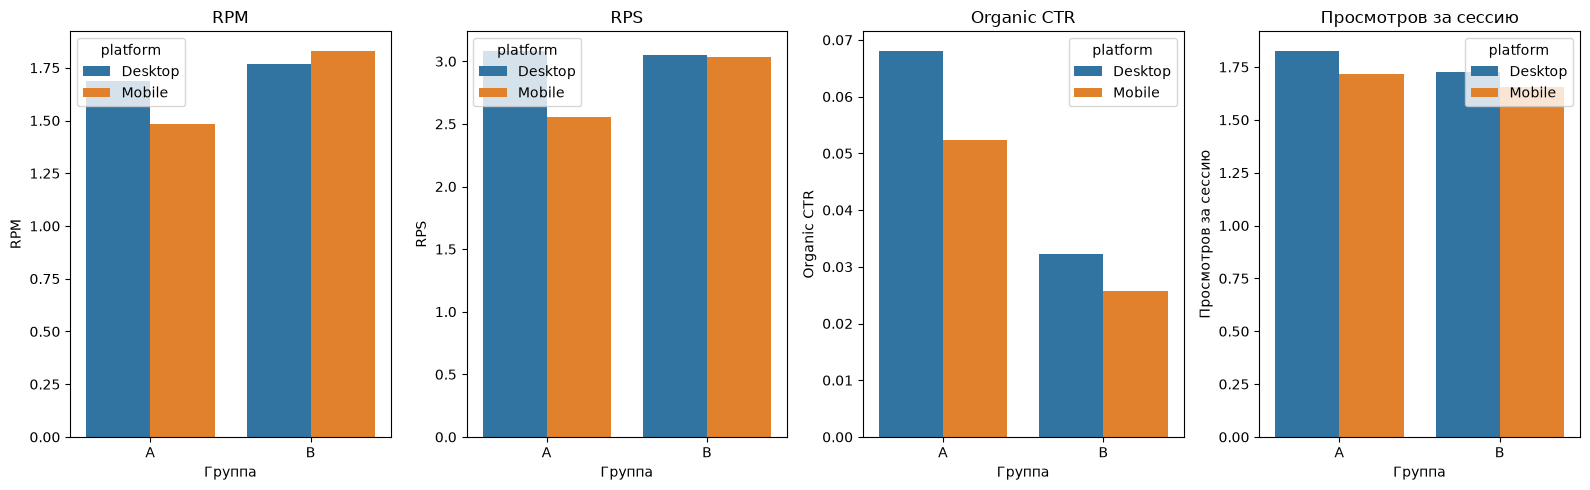

group_name,A,B,diff
visibility,0.283,0.260,-8.13%
paid_ctr,0.017,0.019,11.76%
org_ctr,0.058,0.028,-51.72%
rpm,1.564,1.806,15.47%
rps,2.751,3.039,10.47%
pv_per_sess,1.759,1.682,-4.38%


In [92]:
import os
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = ab_by_platform.reset_index()
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

metrics_to_plot = [
    ('rpm', 'RPM'),
    ('rps', 'RPS'),
    ('org_ctr', 'Organic CTR'),
    ('pv_per_sess', 'Просмотров за сессию'),
]

for ax, (col, title) in zip(axes, metrics_to_plot):
    sns.barplot(data=plot_df, x='group_name', y=col, hue='platform', ax=ax)
    ax.set(title=title, xlabel='Группа', ylabel=title)

plt.tight_layout()
os.makedirs('images', exist_ok=True)
plt.savefig('images/metrics_by_platform.png', dpi=150, bbox_inches='tight')
plt.show()


transposed_a_b = ab_global.transpose().round(3)
transposed_a_b['diff'] = round((transposed_a_b['B'] / transposed_a_b['A'] - 1 )* 100, 2).astype('str') + '%'
transposed_a_b

**Разница B к A в процентах, отдельно по платформам** (`diff_%`):

In [93]:
cols = {}
for plat in ['Desktop', 'Mobile']:
    a = ab_by_platform.loc[(plat, 'A')]
    b = ab_by_platform.loc[(plat, 'B')]
    cols[(plat, 'A')] = a
    cols[(plat, 'B')] = b
    cols[(plat, 'diff_%')] = (b / a - 1) * 100

platform_table = pd.DataFrame(cols).round(2)
platform_table

Desktop              Mobile             
                  A     B diff_%      A     B diff_%
visibility     0.35  0.33  -8.11   0.24  0.22  -7.62
paid_ctr       0.02  0.02   6.26   0.02  0.02  17.19
org_ctr        0.07  0.03 -52.69   0.05  0.03 -50.91
rpm            1.69  1.77   4.62   1.49  1.83  23.29
rps            3.09  3.05  -1.16   2.55  3.03  18.79
pv_per_sess    1.83  1.73  -5.52   1.72  1.66  -3.64

## Выводы

**Общий результат (B к A):** RPM **+15,5%**, RPS **+10,5%**, Paid CTR **+11,8%**. Органический CTR упал почти вдвое (**−51,7%**), просмотры за сессию снизились на **4,4%**, Visibility Rate на **8,1%**. Платные блоки наверху зарабатывают больше, а органика теряет много кликов.

**По платформам результат разный:**

| | Desktop | Mobile |
|---|---|---|
| RPM | +4,6% | +23,3% |
| RPS | −1,2% | +18,8% |
| Просмотров за сессию | −5,5% | −3,6% |
| Organic CTR | −52,7% | −50,9% |

**Трейд-офф.** На Mobile рост дохода (RPS +19%) перевешивает небольшую потерю глубины чтения (−3,6%). На Desktop дохода на сессию практически не прибавилось (−1,2%), а просмотров за сессию стало меньше на 5,5%. Общий рост RPS в основном обеспечен Mobile.

**Рекомендация (предварительная):** B выглядит выгодным на Mobile, на Desktop выгоды не видно.

**Ограничения:**
- Статистическая значимость различий не проверялась. Часть разниц, например RPS на Desktop (−1,2%), может быть шумом.
- Тест шёл 7 дней: эффект новизны и день недели не проверены.
- Доля A по просмотрам 49,1%, по сессиям 48,0%, причина не выяснена.
- Неизвестно, по какой единице делили трафик (страницы, сессии, пользователи).

**Что дальше:** проверить значимость различий после изучения статистики (доверительные интервалы, bootstrap), повторить тест на 3–4 недели, посмотреть эффект по издателям.